In [28]:
import warnings
warnings.filterwarnings("ignore")

import sys
print(sys.executable)

from pathlib import Path
import unicodedata
import re
import matplotlib.pyplot as plt

import pandas as pd
import plotly.express as px
import plotly.io as pio

if "vscode" in pio.renderers:
    pio.renderers.default = "vscode"
else:
    pio.renderers.default = "notebook_connected"

try:
    import geobr
except ImportError as exc:
    raise ImportError("Pacote 'geobr' não encontrado. Instale com: pip install geobr") from exc



/home/anna/tcc/Resultados/.venv/bin/python


In [29]:
CSV_MORTALIDADE = Path("/home/anna/tcc/Tratamento/Mortalidade/tabela_mortalidade_faixa_etaria.csv")  
CSV_CASOS_ANO_DIAGNOSTICO = Path("/home/anna/tcc/Tratamento/Casos/incidencia _ano_diagnostico.csv")
CSV_CASOS_ESCOLARIDADE = Path("/home/anna/tcc/Tratamento/Casos/incidencia _escolaridade.csv")
CSV_CASOS_RACA_COR = Path("/home/anna/tcc/Tratamento/Casos/incidencia _raca_cor.csv")
CSV_CASOS_FAIXA_ETARIA = Path("/home/anna/tcc/Tratamento/Casos/incidencia _faixa_etaria.csv")
CSV_MAMOGRAFIA = Path("/home/anna/tcc/Tratamento/Mamografia/tabela_mamografia.csv")
CSV_RENDA  = Path("/home/anna/tcc/Tratamento/Socioeconômico/tabela_renda.csv")
CSV_RACACOR = Path("/home/anna/tcc/Tratamento/Socioeconômico/tabela_raca_cor.csv")

=== FILTRO ===
Linhas selecionadas: 841
Municípios únicos (amostra): ['alfenas', 'alterosa', 'arceburgo', 'areado', 'bandeira do sul']
Códigos (amostra): [np.int64(3101607), np.int64(3102001), np.int64(3104106), np.int64(3104304), np.int64(3105301)]
Cols usadas para 40-49: 46 (de 46 anos)
=== TABELA (faixa etária como coluna) ===


,Regional de Saúde,Código,Municípios,0-9,10-19,20-29,30-39,40-49,50-59,60-69,70 ou mais
0,Alfenas,3101607,alfenas,0,0,2,12,27,50,44,76
1,Alfenas,3102001,alterosa,0,0,0,1,6,6,4,15
2,Alfenas,3104106,arceburgo,0,0,0,3,6,6,7,6
3,Alfenas,3104304,areado,0,0,0,2,9,6,7,7
4,Alfenas,3105301,bandeira do sul,0,0,0,0,2,2,2,3
5,Alfenas,3108404,botelhos,0,0,0,3,4,7,7,9
6,Alfenas,3109501,cabo verde,0,0,0,3,2,7,4,6
7,Alfenas,3111002,campestre,0,0,0,0,5,11,7,18
8,Alfenas,3111309,campo do meio,0,0,1,2,2,6,3,7
9,Alfenas,3111606,campos gerais,0,0,1,1,7,12,9,17


=== CHECAGEM (mesmo recorte/anos) ===
Intervalo: 1979–2024
Exemplo 40-49 (intervalo): 7.385
Exemplo Total 2023:        1.750
✅ Tooltip ativo (barras e bolinhas)


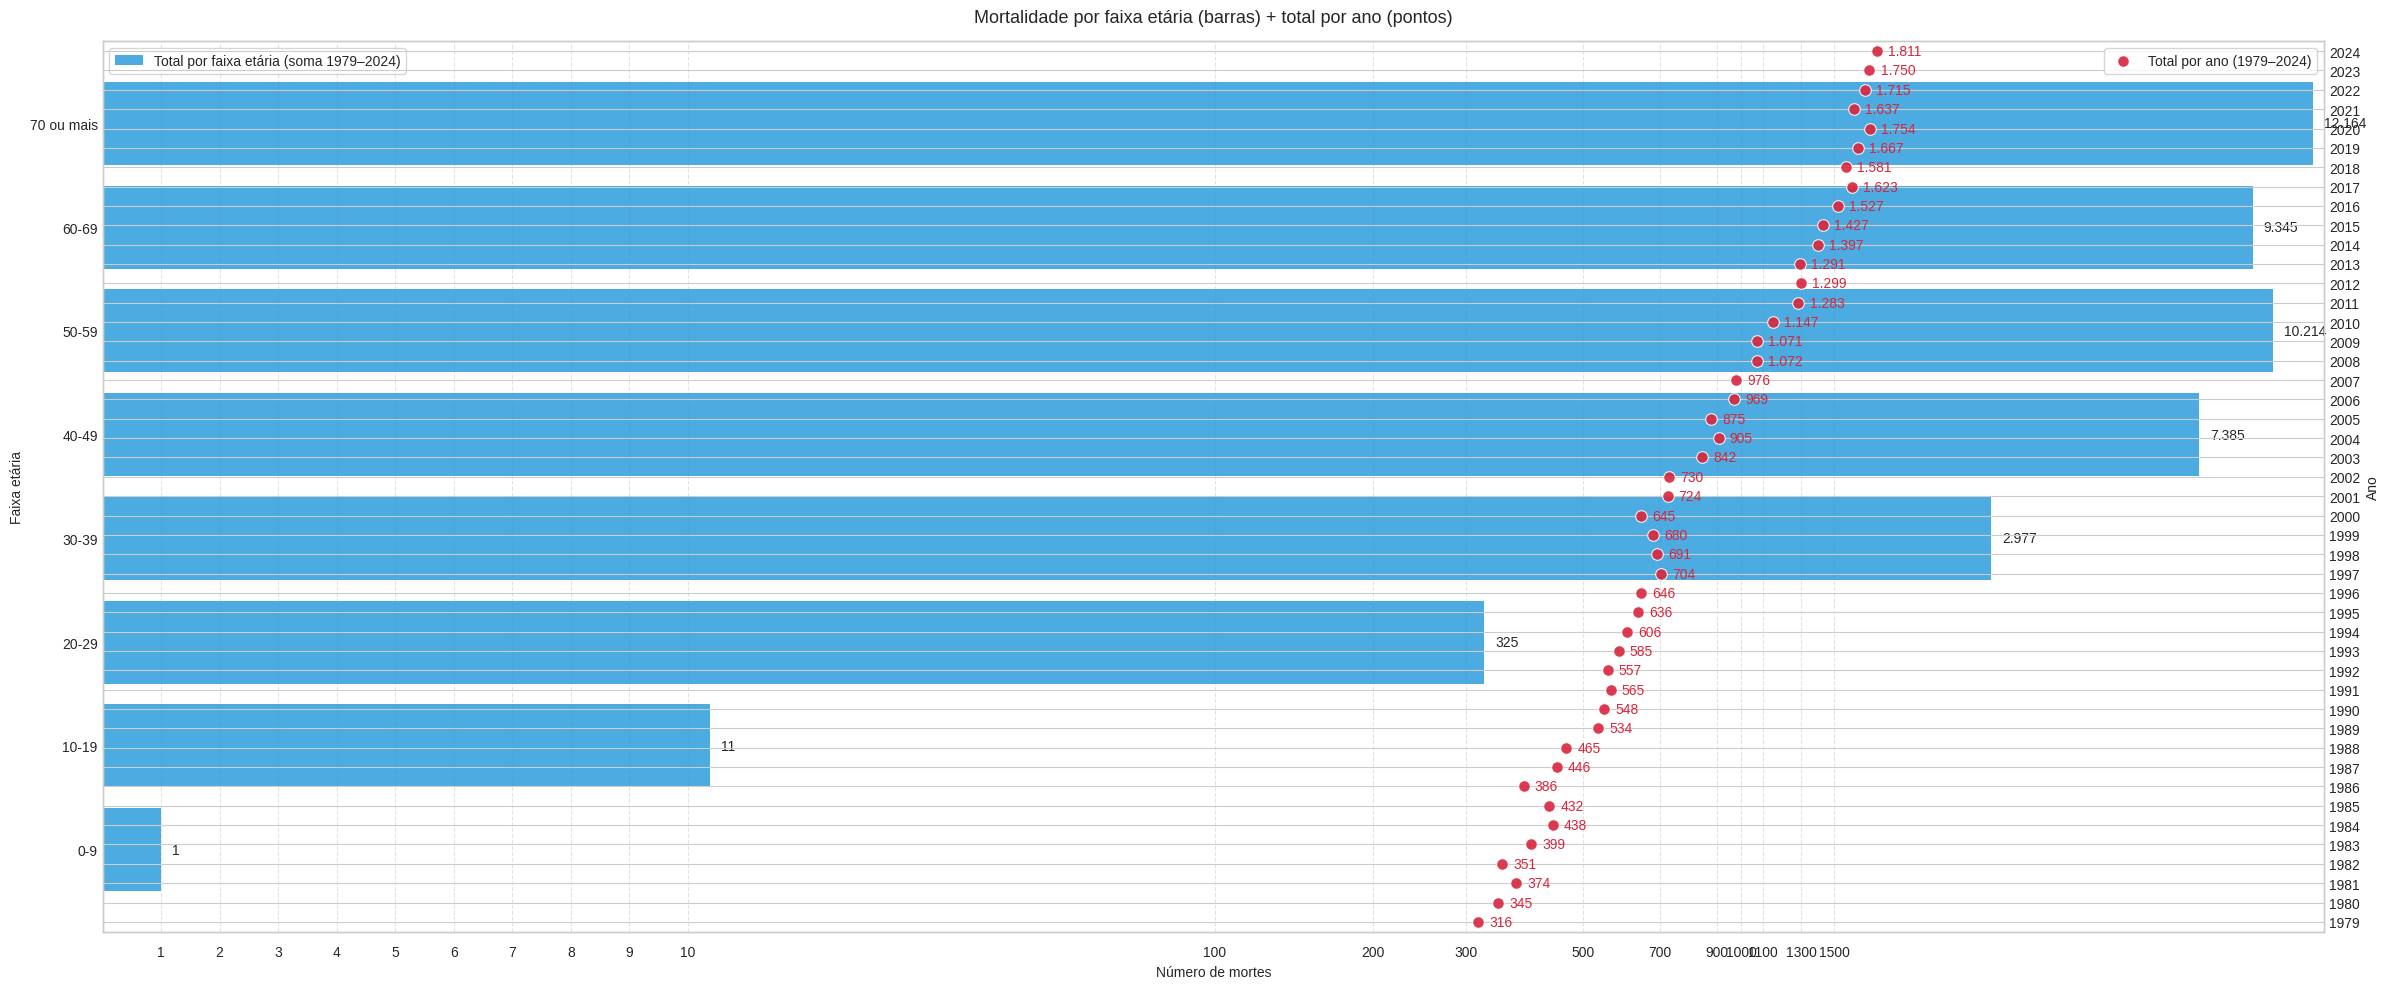

In [ ]:
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Configs (ajuste aqui)
# -------------------------
# O CSV é wide: colunas no formato YYYY_faixa (ex: 1979_40-49) e/ou Total_YYYY.
# Cada linha é um município. Se quiser recortar, ajuste abaixo.
MUNICIPIO = None  # coloque None para somar TODOS os municípios
CODIGO_MUNICIPIO = None       # opcional (ex.: 3106200)
REGIONAL_SAUDE = None         # opcional (ex.: "Alfenas")

# Intervalo de anos (vale para pontos e barras)
ANOS_RANGE = (1979, 2024)
ANOS_PASSO = 1

# Faixas (cada faixa vira UMA coluna na horizontal na tabela abaixo)
FAIXAS_ETARIAS = [
    "0-9", "10-19", "20-29", "30-39",  
    "40-49", "50-59", "60-69", "70 ou mais",
]

# Eixo X — DEFINA OS NÚMEROS AQUI
X_TICKS = list(range(1, 11)) + [100, 200, 300, 500, 700, 900, 1000, 1100, 1300, 1500]
X_MIN = 0

# Escala do X (para os ticks 1..10 aparecerem mesmo com valores grandes)
X_SCALE = "symlog"        # "linear" ou "symlog"
X_LINTHRESH = 10          # região linear até 10
X_LINSCALE = 1.0

# Visual
COR_BARRAS = globals().get("COR_BARRAS", "#2D9CDB")
COR_PONTOS = globals().get("COR_PONTOS", "#D7263D")
COR_GRADE  = globals().get("COR_GRADE",  "#B0B0B0")
TAMANHO_FIG = (24, 10)

MOSTRAR_ROTULOS_BARRAS = True
MOSTRAR_ROTULOS_PONTOS = True
TOOLTIP_ATIVO = True  # usa mplcursors (se estiver instalado)

TITULO = "Mortalidade por faixa etária (barras) + total por ano (pontos)"

# -------------------------
# Helpers
# -------------------------
def _norm_txt(x: str) -> str:
    if x is None:
        return ""
    x = str(x).strip().lower()
    x = unicodedata.normalize("NFKD", x)
    x = "".join(ch for ch in x if not unicodedata.combining(ch))
    return x

def _norm_series(s: pd.Series) -> pd.Series:
    return s.astype(str).map(_norm_txt)

def ticks_inclusive(inicio, fim, passo):
    ticks = list(range(int(inicio), int(fim) + 1, max(1, int(passo))))
    if ticks and ticks[-1] != int(fim):
        ticks.append(int(fim))
    return ticks

def _fmt_int(n):
    try:
        return f"{int(n):,}".replace(",", ".")
    except Exception:
        return str(n)

def _col_ano_faixa(ano: int, faixa: str) -> str:
    return f"{int(ano)}_{faixa}"

def _col_total_ano(ano: int) -> str:
    return f"Total_{int(ano)}"

def _sum_row_wise(frame: pd.DataFrame, cols: list[str]) -> pd.Series:
    """Replica df[col1] + df[col2] + ... (por linha)."""
    if not cols:
        return pd.Series([0] * len(frame), index=frame.index, dtype="int64")
    vals = frame[cols].apply(pd.to_numeric, errors="coerce").fillna(0)
    return vals.sum(axis=1).round().astype(int)

# -------------------------
# Carregar tabela wide (1 linha por município)
# -------------------------
if "df_mortalidade" in globals():
    df = df_mortalidade.copy()
else:
    df = pd.read_csv(CSV_MORTALIDADE)

# Aplica filtro (município/código/regional)
f = df.copy()
if MUNICIPIO is not None:
    alvo = _norm_txt(MUNICIPIO)
    if "Municípios" not in f.columns:
        raise KeyError("Coluna 'Municípios' não existe no CSV.")
    f = f[_norm_series(f["Municípios"]) == alvo]
if CODIGO_MUNICIPIO is not None:
    if "Código" not in f.columns:
        raise KeyError("Coluna 'Código' não existe no CSV.")
    f = f[pd.to_numeric(f["Código"], errors="coerce").astype("Int64") == int(CODIGO_MUNICIPIO)]
if REGIONAL_SAUDE is not None:
    alvo = _norm_txt(REGIONAL_SAUDE)
    if "Regional de Saúde" not in f.columns:
        raise KeyError("Coluna 'Regional de Saúde' não existe no CSV.")
    f = f[_norm_series(f["Regional de Saúde"]) == alvo]

if f.empty:
    raise ValueError("Filtro não encontrou nenhuma linha. Confira MUNICIPIO/CODIGO_MUNICIPIO/REGIONAL_SAUDE.")

# Garantia: se MUNICIPIO foi definido, a seleção PRECISA ser só daquele município
if MUNICIPIO is not None:
    chec = _norm_series(f["Municípios"])
    if not (chec == _norm_txt(MUNICIPIO)).all():
        amostra = f[["Municípios", "Código"]].head(10) if "Código" in f.columns else f[["Municípios"]].head(10)
        raise ValueError("Filtro de MUNICIPIO falhou (seleção contém municípios diferentes). Amostra:\n" + amostra.to_string(index=False))

print("=== FILTRO ===")
print(f"Linhas selecionadas: {len(f)}")
if "Municípios" in f.columns:
    print("Municípios únicos (amostra):", list(f["Municípios"].dropna().astype(str).unique()[:5]))
if "Código" in f.columns:
    print("Códigos (amostra):", list(pd.to_numeric(f["Código"], errors="coerce").dropna().astype(int).unique()[:5]))

# -------------------------
# Somatórios (SEM taxa, só soma)
# -------------------------
ano_ini, ano_fim = map(int, ANOS_RANGE)
anos = list(range(ano_ini, ano_fim + 1))

# 1) TABELA: cada faixa = UMA coluna horizontal (por linha/município)
df_faixas_por_linha = pd.DataFrame(index=f.index)
for fx in FAIXAS_ETARIAS:
    cols_fx = [_col_ano_faixa(ano, fx) for ano in anos if _col_ano_faixa(ano, fx) in f.columns]
    df_faixas_por_linha[fx] = _sum_row_wise(f, cols_fx)

# Debug específico pra faixa 40-49 (pra bater com sua soma manual)
cols_4049 = [_col_ano_faixa(ano, "40-49") for ano in anos if _col_ano_faixa(ano, "40-49") in f.columns]
print(f"Cols usadas para 40-49: {len(cols_4049)} (de {len(anos)} anos)")
if len(cols_4049) < len(anos):
    anos_presentes = {int(c.split("_", 1)[0]) for c in cols_4049}
    faltando = [ano for ano in anos if ano not in anos_presentes]
    print("Anos faltando na faixa 40-49 (sem coluna no CSV):", faltando[:30], "..." if len(faltando) > 30 else "")

# Adiciona identificadores (se existirem) para facilitar conferência
for col_id in ["Municípios", "Código", "Regional de Saúde"]:
    if col_id in f.columns and col_id not in df_faixas_por_linha.columns:
        df_faixas_por_linha.insert(0, col_id, f[col_id].values)

print("=== TABELA (faixa etária como coluna) ===")
display(df_faixas_por_linha.head(10))

# 2) BARRAS (Y esquerdo): soma das colunas da tabela
por_faixa = df_faixas_por_linha[FAIXAS_ETARIAS].sum(axis=0).astype(int)

# 3) PONTOS (Y direito): total por ano (preferindo Total_YYYY, se existir)
por_ano = {}
for ano in anos:
    col_total = _col_total_ano(ano)
    if col_total in f.columns:
        por_ano[ano] = int(pd.to_numeric(f[col_total], errors="coerce").fillna(0).sum())
    else:
        cols = [_col_ano_faixa(ano, fx) for fx in FAIXAS_ETARIAS if _col_ano_faixa(ano, fx) in f.columns]
        por_ano[ano] = int(_sum_row_wise(f, cols).sum())
por_ano = pd.Series(por_ano).sort_index()

print("=== CHECAGEM (mesmo recorte/anos) ===")
print(f"Intervalo: {ano_ini}–{ano_fim}")
print(f"Exemplo 40-49 (intervalo): {_fmt_int(int(por_faixa.get('40-49', 0)))}")
if 2023 in por_ano.index:
    print(f"Exemplo Total 2023:        {_fmt_int(int(por_ano.loc[2023]))}")

# -------------------------
# Limites do X
# -------------------------
x_max = int(max(int(por_faixa.max()), int(por_ano.max())))
x_max = max(x_max, max(X_TICKS) if X_TICKS else 1)
x_min_for_scale = 0.0001 if X_SCALE == "symlog" else X_MIN

# -------------------------
# Plot (dois eixos Y, mesmo eixo X)
# -------------------------
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax1 = plt.subplots(figsize=TAMANHO_FIG)

if X_SCALE == "symlog":
    ax1.set_xscale("symlog", linthresh=X_LINTHRESH, linscale=X_LINSCALE, base=10)
elif X_SCALE != "linear":
    raise ValueError("X_SCALE precisa ser 'linear' ou 'symlog'.")

barras = ax1.barh(
    FAIXAS_ETARIAS,
    por_faixa.reindex(FAIXAS_ETARIAS).values.tolist(),
    color=COR_BARRAS,
    alpha=0.85,
    label=f"Total por faixa etária (soma {ano_ini}–{ano_fim})",
    zorder=2,
)
ax1.set_xlabel("Número de mortes")
ax1.set_ylabel("Faixa etária")
ax1.set_xlim(x_min_for_scale, x_max * 1.05)

xticks = [t for t in X_TICKS if X_MIN <= t <= x_max]
ax1.set_xticks(xticks)
ax1.set_xticklabels([str(t) for t in xticks])
ax1.tick_params(axis="x", labelsize=10, pad=10)
ax1.grid(axis="x", linestyle="--", linewidth=0.8, alpha=0.35, color=COR_GRADE)
ax1.grid(axis="y", visible=False)
ax1.set_axisbelow(True)

ax2 = ax1.twinx()
valores_x = por_ano.values.tolist()
valores_y = por_ano.index.tolist()
scatter = ax2.scatter(
    valores_x,
    valores_y,
    color=COR_PONTOS,
    s=70,
    alpha=0.9,
    edgecolors="white",
    linewidths=0.8,
    label=f"Total por ano ({ano_ini}–{ano_fim})",
    zorder=3,
)
ax2.set_ylabel("Ano")
ax2.set_ylim(ano_ini - 0.5, ano_fim + 0.5)
ax2.set_yticks(ticks_inclusive(ano_ini, ano_fim, ANOS_PASSO))
ax2.tick_params(axis="y", labelsize=10)

# -------------------------
# Valores exatos (rótulos)
# -------------------------
if MOSTRAR_ROTULOS_BARRAS:
    for rect in barras.patches:
        val = int(round(rect.get_width()))
        if val <= 0:
            continue
        ax1.annotate(
            _fmt_int(val),
            (val, rect.get_y() + rect.get_height() / 2),
            textcoords="offset points",
            xytext=(8, 0),
            va="center",
            ha="left",
            fontsize=10,
)

if MOSTRAR_ROTULOS_PONTOS:
    for ano, val in por_ano.items():
        val = int(val)
        if val <= 0:
            continue
        ax2.annotate(
            _fmt_int(val),
            (val, int(ano)),
            textcoords="offset points",
            xytext=(8, 0),
            va="center",
            ha="left",
            fontsize=10,
            color=COR_PONTOS,
)

# -------------------------
# Tooltip (barras + bolinhas)
# -------------------------
if TOOLTIP_ATIVO:
    try:
        import mplcursors  # type: ignore

        barra_info = {}
        for patch, faixa in zip(barras.patches, FAIXAS_ETARIAS):
            barra_info[patch] = (faixa, int(round(patch.get_width())))

        cursor = mplcursors.cursor([scatter] + list(barras.patches), hover=mplcursors.HoverMode.Transient)

        @cursor.connect("add")
        def _tooltip(sel):
            artist = sel.artist
            if artist is scatter:
                idx = int(sel.index)
                x_val = valores_x[idx]
                y_val = valores_y[idx]
                sel.annotation.set_text(f"Ano: {y_val}\nMortes: {_fmt_int(x_val)}")
            else:
                faixa, v = barra_info.get(artist, ("Faixa", int(round(getattr(artist, "get_width", lambda: 0)()))))
                sel.annotation.set_text(f"Faixa: {faixa}\nMortes: {_fmt_int(v)}")
            sel.annotation.get_bbox_patch().set(facecolor="white", alpha=0.95)

        print("✅ Tooltip ativo (barras e bolinhas)")
    except Exception as exc:
        print("⚠️  Tooltip não ativo:", exc)

ax1.legend(loc="upper left", frameon=True)
ax2.legend(loc="upper right", frameon=True)
plt.title(TITULO, fontsize=13, pad=14)

fig.subplots_adjust(bottom=0.18)
plt.tight_layout()
plt.show()